# 01 · Variable Gobierno / Oposición

**Objetivo.** La hipótesis de la Entrega 2 es:

> **H1:** Las intervenciones de las familias políticas presentan, en promedio, puntuaciones de sentimiento más negativas durante los periodos en los que ejercen la oposición que durante aquellos en los que forman parte del Gobierno, dentro del intervalo 2016–2026.

Para contrastarla hace falta saber, para cada intervención, si el partido del orador estaba en el Gobierno ese día. En la Entrega 2 no existía esta variable, así que este notebook la construye a partir de `data/periodos_gobierno.csv`, una tabla escrita a mano con las fechas de cada cambio de Gobierno.

**Salidas:**
- `data/intervenciones_gobierno.parquet`: una fila por intervención, con el rol del partido y si quien habla es miembro del Gobierno.
- `data/panel_partido_mes.csv`: una fila por mes y partido. Es la entrada de los notebooks de series temporales.
- `results/01_cronologia_gobierno.png` y `results/01_resumen_gobierno_oposicion.csv`.

Los datos de la Entrega 2 se leen de `../corpus-indicators/` y no se modifican.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
E2 = ROOT.parent / "corpus-indicators" / "data" / "processed"   # salidas de la Entrega 2
DATA, RESULTS = ROOT / "data", ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)
PARTIDOS = ["PP", "PSOE", "Podemos-UP-Sumar", "VOX", "Cs"]

## 1. Periodos de Gobierno

Criterios:
- **Se codifica la familia política**, no a cada diputado: un partido está en el Gobierno si tiene ministros.
- **Los Gobiernos en funciones cuentan como Gobierno** (Rajoy hasta octubre de 2016; Sánchez en 2019 y en 2023).
- **Un `fin` vacío significa que el periodo sigue vigente** al final del corpus (septiembre de 2026).
- **El cambio se fecha el día de la toma de posesión**: el 2-6-2018 para Sánchez y el 13-1-2020 para los ministros de Unidas Podemos. Así, el debate de la moción de censura (31-5 y 1-6-2018) y el de investidura de enero de 2020 (4–7 de enero) cuentan todavía con los papeles anteriores.
- **El apoyo parlamentario sin ministros es oposición**: Cs con Rajoy en 2016–2018 y Unidas Podemos con Sánchez I en 2018–2019. Esto es discutible y se recoge como limitación.
- **Desde diciembre de 2023 Podemos deja el grupo Sumar.** En el corpus, la familia `Podemos-UP-Sumar` solo contiene intervenciones del grupo `GSUMAR` desde entonces (se comprueba más abajo), así que sigue siendo Gobierno.

In [2]:
periodos = pd.read_csv(DATA / "periodos_gobierno.csv", parse_dates=["inicio", "fin"])
periodos

,party,rol,inicio,fin,descripcion
0,PP,gobierno,2016-01-01,2018-06-01,Gobierno Rajoy (en funciones hasta la investidura del 29-10-2016). Termina con la moción de censura aproba...
1,PP,oposicion,2018-06-02,NaT,En la oposición desde la toma de posesión de Pedro Sánchez (2-6-2018)
2,PSOE,oposicion,2016-01-01,2018-06-01,En la oposición durante el Gobierno Rajoy
3,PSOE,gobierno,2018-06-02,NaT,"Gobiernos Sánchez I (2018), II (coalición, 2020) y III (coalición, 2023); incluye los periodos en funciones"
4,Podemos-UP-Sumar,oposicion,2016-01-01,2020-01-12,"En la oposición, incluido el apoyo externo al Gobierno Sánchez I y la investidura de enero de 2020"
5,Podemos-UP-Sumar,gobierno,2020-01-13,NaT,Ministros de Unidas Podemos desde el 13-1-2020 (Gobierno de coalición) y de Sumar desde el 21-11-2023
6,VOX,oposicion,2016-01-01,NaT,Nunca en el Gobierno central
7,Cs,oposicion,2016-01-01,NaT,"Nunca en el Gobierno central (apoyo parlamentario a Rajoy en la legislatura XII, sin ministros)"


## 2. Asignar el rol a cada intervención

In [3]:
cols = ["id", "date", "month", "party", "parliamentary_group", "speaker_name", "speaker_role",
        "legislature", "eligible_nlp", "sentiment", "p_neg", "p_neu", "p_pos", "mattr"]
df = pd.read_parquet(E2 / "interventions_indicators.parquet", columns=cols)
df["date"] = pd.to_datetime(df["date"])

def rol_en_fecha(party, fecha):
    fila = periodos[(periodos.party == party) & (periodos.inicio <= fecha) & (periodos.fin.isna() | (periodos.fin >= fecha))]
    assert len(fila) == 1, f"Periodos solapados o ausentes: {party} {fecha:%Y-%m-%d}"
    return fila.rol.iloc[0]

df["rol_partido"] = [rol_en_fecha(p, f) for p, f in zip(df.party, df.date)]
df["gobierno"] = df.rol_partido.eq("gobierno").astype(int)
pd.crosstab(df.party, df.rol_partido, margins=True)

rol_partido,gobierno,oposicion,All
party,,,
Cs,0,498,498
PP,907,2492,3399
PSOE,2449,440,2889
Podemos-UP-Sumar,1172,623,1795
VOX,0,1419,1419
All,4528,5472,10000


## 3. ¿Habla un miembro del Gobierno o un diputado?

En los partidos de Gobierno, una parte de las intervenciones son de ministros o del presidente que responden en las sesiones de control. Su tono puede diferir del de los diputados por el cargo y no solo por el partido. Por eso se marca a quienes son **miembros del Gobierno** según `speaker_role`. Los candidatos a la investidura no cuentan, porque aún no forman parte del Gobierno.

In [4]:
patron = r"(?i)ministr|presidente del gobierno|vicepresident"
df["miembro_gobierno"] = (df.speaker_role.fillna("").str.contains(patron)
                          & ~df.speaker_role.fillna("").str.contains(r"(?i)candidat|comisi")).astype(int)
df.groupby(["party", "rol_partido"]).miembro_gobierno.agg(["sum", "mean"]).rename(
    columns={"sum": "n_miembros_gobierno", "mean": "proporcion"}).round(3)

n_miembros_gobierno  proporcion
party            rol_partido                                 
Cs               oposicion                      0       0.000
PP               gobierno                     594       0.655
                 oposicion                      0       0.000
PSOE             gobierno                    1222       0.499
                 oposicion                      0       0.000
Podemos-UP-Sumar gobierno                     175       0.149
                 oposicion                      0       0.000
VOX              oposicion                      0       0.000

**Comprobación de coherencia:** un miembro del Gobierno solo puede pertenecer a un partido que esté en el Gobierno en esa fecha. Si hubiera filas aquí, la tabla de periodos o el patrón estarían mal.

In [5]:
incoherentes = df[(df.miembro_gobierno == 1) & (df.gobierno == 0)]
print("Miembros del Gobierno en partidos de la oposición:", len(incoherentes))
incoherentes[["date", "party", "speaker_name", "speaker_role"]]

Miembros del Gobierno en partidos de la oposición: 0


,date,party,speaker_name,speaker_role


**Comprobación de la familia Sumar:** desde el 1-12-2023, todas las intervenciones de `Podemos-UP-Sumar` deberían pertenecer al grupo de Sumar y no al grupo Mixto.

In [6]:
s = df[(df.party == "Podemos-UP-Sumar") & (df.date >= "2023-12-01")]
s.parliamentary_group.value_counts()

parliamentary_group
GSUMAR                                     461
Grupo Parlamentario Plurinacional SUMAR      4
Name: count, dtype: int64

Se guarda la tabla por intervención (sin texto) para los notebooks siguientes.

In [7]:
df.to_parquet(DATA / "intervenciones_gobierno.parquet", index=False)
df.shape

(10000, 17)

## 4. Cronología

Cada franja muestra el rol del partido y los puntos, el número de intervenciones de la muestra por mes.

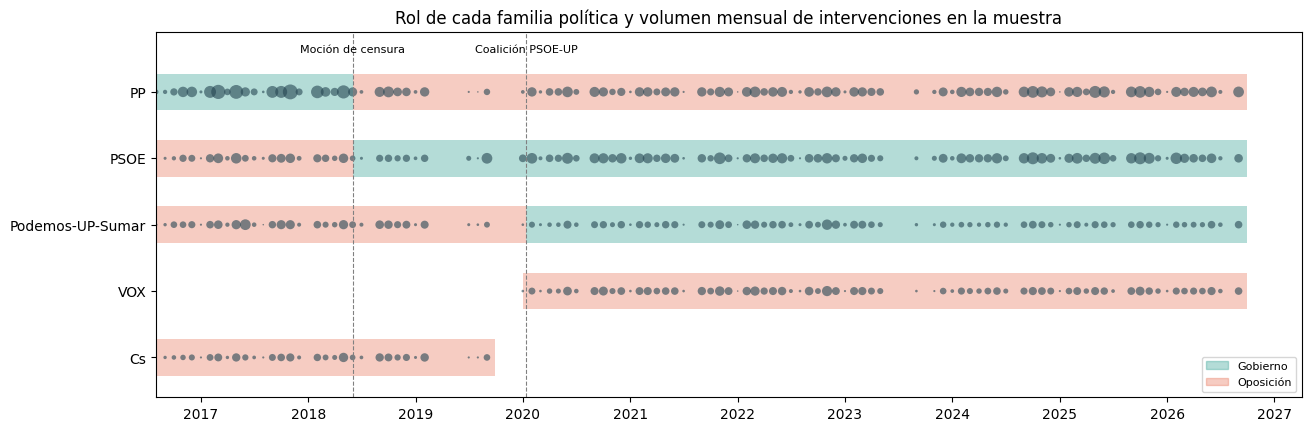

In [8]:
mensual = df.groupby(["party", "month"]).size().rename("n").reset_index()
mensual["fecha"] = pd.to_datetime(mensual.month)
colores = {"gobierno": "#2a9d8f", "oposicion": "#e76f51"}

fig, ax = plt.subplots(figsize=(13, 4.2), layout="constrained")
for i, p in enumerate(PARTIDOS[::-1]):
    # La franja cubre solo los meses en que el partido tiene intervenciones en la muestra
    fechas = mensual.loc[mensual.party == p, "fecha"]
    inicio, fin = fechas.min(), fechas.max() + pd.offsets.MonthEnd(0)
    for _, r in periodos[periodos.party == p].iterrows():
        a, b = max(r.inicio, inicio), (fin if pd.isna(r.fin) else min(r.fin, fin))
        if a < b:
            ax.barh(i, b - a, left=a, height=.55, color=colores[r.rol], alpha=.35)
    m = mensual[mensual.party == p]
    ax.scatter(m.fecha, np.full(len(m), i), s=m.n * 1.2, color="#264653", alpha=.6, linewidths=0)
for fecha, texto in [("2018-06-02", "Moción de censura"), ("2020-01-13", "Coalición PSOE-UP")]:
    ax.axvline(pd.Timestamp(fecha), color="gray", ls="--", lw=.8)
    ax.text(pd.Timestamp(fecha), len(PARTIDOS) - .4, texto, fontsize=8, ha="center")
ax.set_yticks(range(len(PARTIDOS)), PARTIDOS[::-1])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(-.6, len(PARTIDOS) - .1)
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=.35) for c in colores.values()]
ax.legend(handles, ["Gobierno", "Oposición"], loc="lower right", fontsize=8)
ax.set_title("Rol de cada familia política y volumen mensual de intervenciones en la muestra")
fig.savefig(RESULTS / "01_cronologia_gobierno.png", dpi=160)
plt.show()

## 5. Panel mensual partido × mes

Este panel es la entrada de los notebooks de series temporales. Por cada mes y partido:

| Columna | Significado |
|---|---|
| `n_turns` | Intervenciones de la muestra (0 si no hay ninguna) |
| `n_sentiment`, `sentiment` | Intervenciones con sentimiento y su media (igual que `monthly_party.csv` de la Entrega 2) |
| `n_diputados`, `sentiment_diputados` | Lo mismo, pero sin los miembros del Gobierno |
| `n_miembros_gobierno` | Intervenciones de ministros o del presidente |
| `mattr` | MATTR medio |
| `gobierno` | 1 si el partido está en el Gobierno ese mes, 0 si no |

**Criterio para `gobierno` en un mes:** se mira el rol del partido el día 15. Solo dos meses tienen un cambio de rol dentro del mes: junio de 2018 (cambio el día 2, así que gana el rol nuevo) y enero de 2020 (cambio el día 13). En enero de 2020, todas las intervenciones de Podemos son del debate de investidura, anterior al día 13. Por eso, en los meses con intervenciones se usa el rol mayoritario entre ellas, y en los meses vacíos, el del día 15. La variable debe existir en todos los meses porque SARIMAX no admite huecos en las variables exógenas.

Los meses sin intervenciones se mantienen con valor vacío (`NaN`) en los indicadores, sin interpolar.

In [9]:
calendario = pd.period_range(df.date.min(), df.date.max(), freq="M").astype(str)
indice = pd.MultiIndex.from_product([calendario, PARTIDOS], names=["month", "party"])
dip = df[df.miembro_gobierno == 0]

g = df.groupby(["month", "party"])
panel = pd.DataFrame({
    "n_turns": g.size(),
    "n_sentiment": g.sentiment.count(),
    "sentiment": g.sentiment.mean(),
    "n_miembros_gobierno": g.miembro_gobierno.sum(),
    "n_diputados": dip.groupby(["month", "party"]).sentiment.count(),
    "sentiment_diputados": dip.groupby(["month", "party"]).sentiment.mean(),
    "mattr": g.mattr.mean(),
    "gobierno_turnos": g.gobierno.mean(),
}).reindex(indice)
for c in ["n_turns", "n_sentiment", "n_miembros_gobierno", "n_diputados"]:
    panel[c] = panel[c].fillna(0).astype(int)
panel = panel.reset_index()

dia15 = [rol_en_fecha(p, pd.Timestamp(m + "-15")) == "gobierno" for m, p in zip(panel.month, panel.party)]
panel["gobierno"] = np.where(panel.gobierno_turnos.notna(), panel.gobierno_turnos.round(), dia15).astype(int)
mixtos = panel[panel.gobierno_turnos.between(0.01, 0.99)]
print("Meses con intervenciones de ambos roles:", len(mixtos))
panel = panel.drop(columns="gobierno_turnos")
panel.to_csv(DATA / "panel_partido_mes.csv", index=False)
print(panel.shape)
panel.head(10)

Meses con intervenciones de ambos roles: 2
(610, 10)


,month,party,n_turns,n_sentiment,sentiment,n_miembros_gobierno,n_diputados,sentiment_diputados,mattr,gobierno
0,2016-08,PP,11,11,-0.120443,0,11,-0.120443,0.682580,1
1,2016-08,PSOE,2,2,-0.338961,0,2,-0.338961,0.678922,0
2,2016-08,Podemos-UP-Sumar,4,4,-0.410971,0,4,-0.410971,0.675905,0
3,2016-08,VOX,0,0,NaN,0,0,NaN,NaN,0
4,2016-08,Cs,2,2,-0.140894,0,2,-0.140894,0.681075,0
5,2016-09,PP,8,8,-0.253901,0,8,-0.253901,0.667292,1
6,2016-09,PSOE,4,4,-0.478991,0,4,-0.478991,0.673480,0
7,2016-09,Podemos-UP-Sumar,5,5,-0.422080,0,5,-0.422080,0.677144,0
8,2016-09,VOX,0,0,NaN,0,0,NaN,NaN,0
9,2016-09,Cs,5,5,-0.296815,0,5,-0.296815,0.689205,0


**Comprobación frente a la Entrega 2:** el sentimiento mensual recalculado debe coincidir con `monthly_party.csv`.

In [10]:
e2 = pd.read_csv(E2 / "monthly_party.csv")[["month", "party", "n_turns", "sentiment"]]
cmp = panel.merge(e2, on=["month", "party"], suffixes=("", "_e2"))
assert len(cmp) == len(panel)
assert (cmp.n_turns == cmp.n_turns_e2).all()
assert np.allclose(cmp.sentiment, cmp.sentiment_e2, equal_nan=True)
print("OK: coincide con monthly_party.csv de la Entrega 2")

OK: coincide con monthly_party.csv de la Entrega 2


**Cobertura de las series:** cuántos meses con dato hay en cada rol. Es lo que limita qué se puede modelar después.

In [11]:
cobertura = (panel[panel.n_sentiment > 0].groupby(["party", "gobierno"])
             .agg(meses=("month", "size"), mediana_turnos_mes=("n_sentiment", "median"),
                  desde=("month", "min"), hasta=("month", "max")))
cobertura

meses  mediana_turnos_mes    desde    hasta
party            gobierno                                             
Cs               0            32                15.5  2016-08  2019-09
PP               0            83                34.0  2018-06  2026-09
                 1            21                40.0  2016-08  2018-05
PSOE             0            21                20.0  2016-08  2018-05
                 1            83                30.0  2018-06  2026-09
Podemos-UP-Sumar 0            33                19.0  2016-08  2020-01
                 1            71                16.0  2020-02  2026-09
VOX              0            72                21.5  2020-01  2026-09

## 6. Primera mirada descriptiva (todavía no es el contraste)

Media del sentimiento por intervención en cada rol. Solo es orientativa: no controla la tendencia temporal ni la autocorrelación, que es justo lo que harán los modelos de los pasos siguientes. La columna `diferencia` es Gobierno − Oposición; H1 predice que sea **positiva**.

In [12]:
def resumen(d, etiqueta):
    t = d[d.sentiment.notna()].groupby(["party", "rol_partido"]).sentiment.agg(["size", "mean"]).unstack()
    t.columns = [f"{a}_{b}" for a, b in t.columns]
    t = t.rename(columns={"size_gobierno": "n_gob", "size_oposicion": "n_opo",
                          "mean_gobierno": "sent_gob", "mean_oposicion": "sent_opo"})
    t["diferencia"] = t.sent_gob - t.sent_opo
    t.insert(0, "muestra", etiqueta)
    return t

tabla = pd.concat([resumen(df, "todas las intervenciones"),
                   resumen(df[df.miembro_gobierno == 0], "solo diputados")]).reindex(columns=[
    "muestra", "n_gob", "sent_gob", "n_opo", "sent_opo", "diferencia"])
tabla.to_csv(RESULTS / "01_resumen_gobierno_oposicion.csv")
tabla.round(3)

,muestra,n_gob,sent_gob,n_opo,sent_opo,diferencia
party,,,,,,
Cs,todas las intervenciones,NaN,NaN,497.0,-0.277,NaN
PP,todas las intervenciones,905.0,0.013,2492.0,-0.404,0.416
PSOE,todas las intervenciones,2446.0,-0.177,436.0,-0.300,0.123
Podemos-UP-Sumar,todas las intervenciones,1165.0,-0.255,613.0,-0.359,0.104
VOX,todas las intervenciones,NaN,NaN,1419.0,-0.447,NaN
Cs,solo diputados,NaN,NaN,497.0,-0.277,NaN
PP,solo diputados,311.0,-0.111,2492.0,-0.404,0.292
PSOE,solo diputados,1224.0,-0.199,436.0,-0.300,0.101
Podemos-UP-Sumar,solo diputados,990.0,-0.268,613.0,-0.359,0.091


## 7. Resumen

- La variable se construye a partir de los cambios de Gobierno de 2018 y 2020. **Tres familias cambian de rol** (PP, PSOE y Podemos-UP-Sumar), y **VOX y Cs están siempre en la oposición**, así que sirven de referencia de cómo evoluciona el tono sin cambio de rol.
- Las comprobaciones de coherencia (ningún ministro en un partido de la oposición, la familia Sumar y la coincidencia con la Entrega 2) se superan.
- Se separa a los **miembros del Gobierno** de los diputados porque mezclar ambos podría confundir el efecto del rol con el del cargo.
- El panel `data/panel_partido_mes.csv` queda listo para la exploración temporal (notebook 02).